In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings('ignore')


In [ ]:
df = pd.read_csv("ai4i2020.csv")

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["Type"].unique()

array(['M', 'L', 'H'], dtype=object)

In [ ]:
df["Machine failure"].value_counts()

,count
Machine failure,
0,9661
1,339


In [ ]:
df["Machine failure"].value_counts(normalize=True) * 100

,proportion
Machine failure,
0,96.61
1,3.39


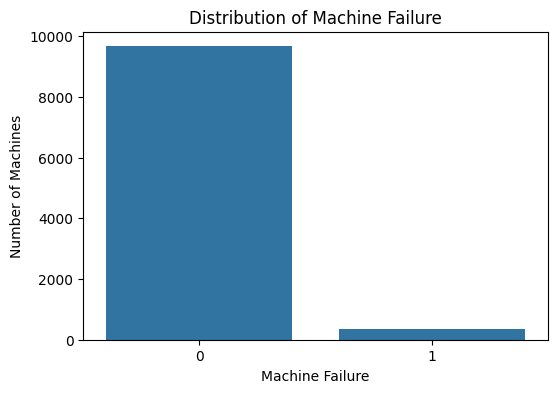

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(
    x="Machine failure",
    data=df
)

plt.title("Distribution of Machine Failure")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Machines")

plt.show()

In [ ]:
numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

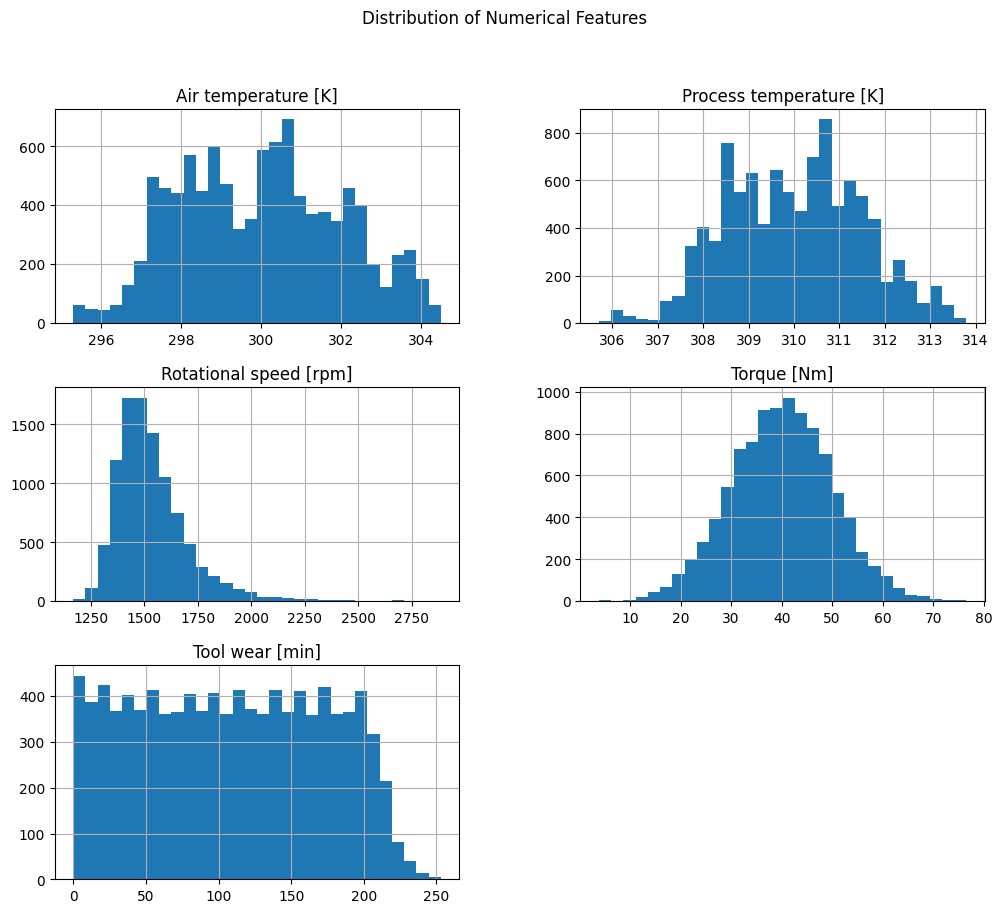

In [ ]:
df[numerical_features].hist(figsize=(12, 10), bins = 30)
plt.suptitle("Distribution of Numerical Features")
plt.show()

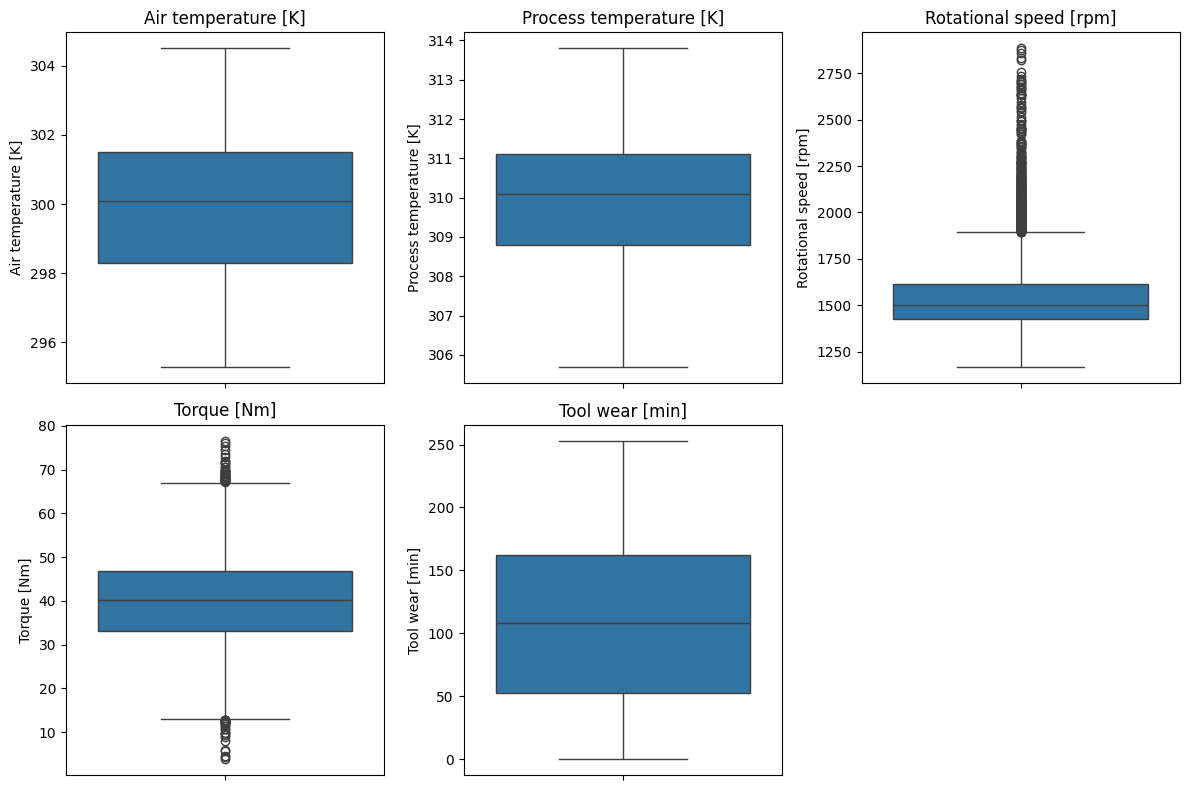

In [ ]:
plt.figure(figsize=(12, 8))

for i, column in enumerate(numerical_features, 1):

  plt.subplot(2, 3, i)

  sns.boxplot(y = df[column])

  plt.title(column)

plt.tight_layout()
plt.show()

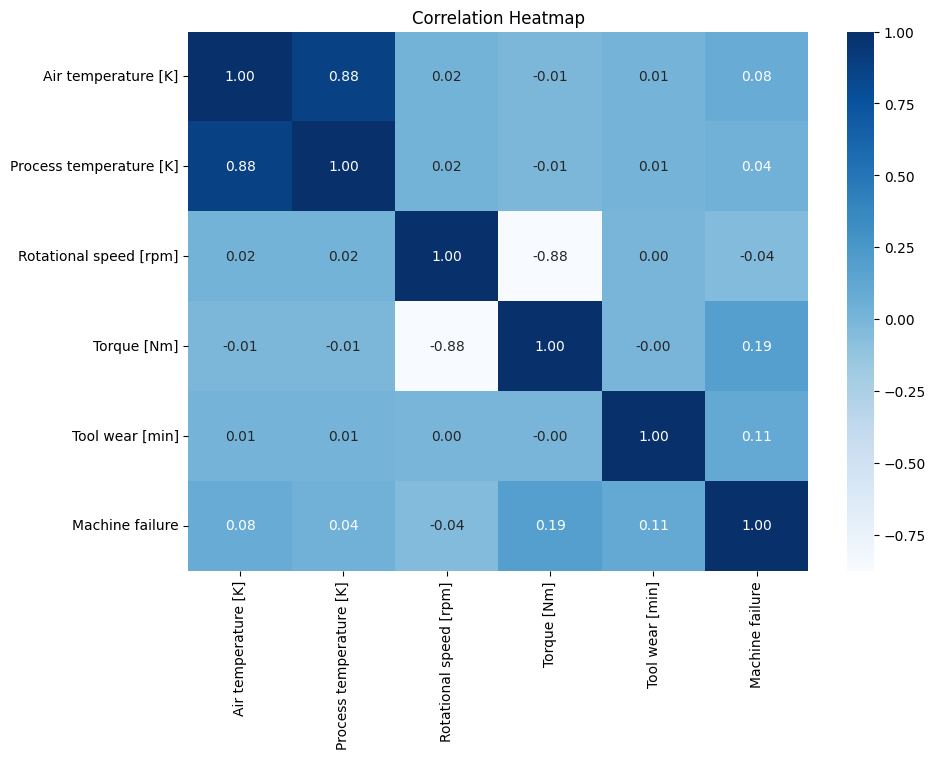

In [ ]:
plt.figure(figsize=(10, 7))

correlation = df[numerical_features + ["Machine failure"]].corr()

sns.heatmap(correlation, annot = True, cmap = "Blues", fmt = ".2f")

plt.title("Correlation Heatmap")

plt.show()

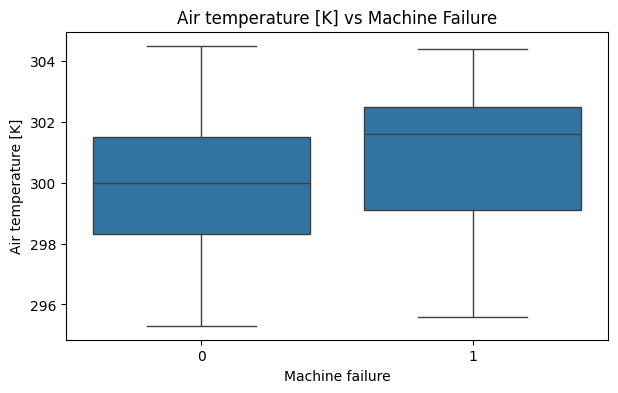

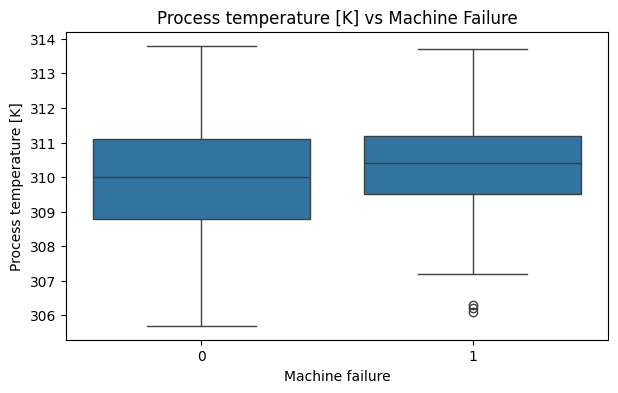

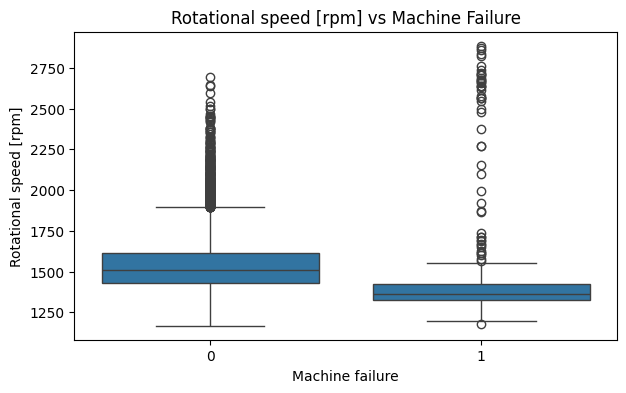

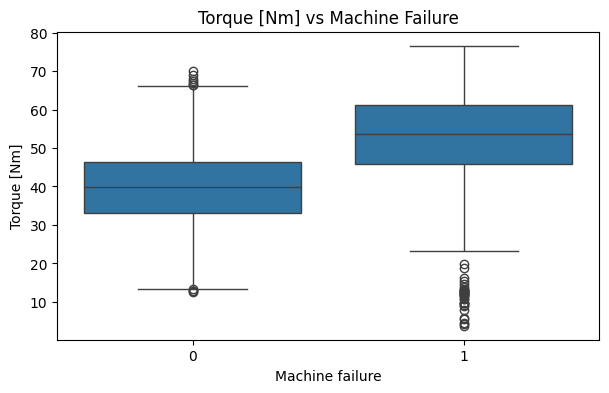

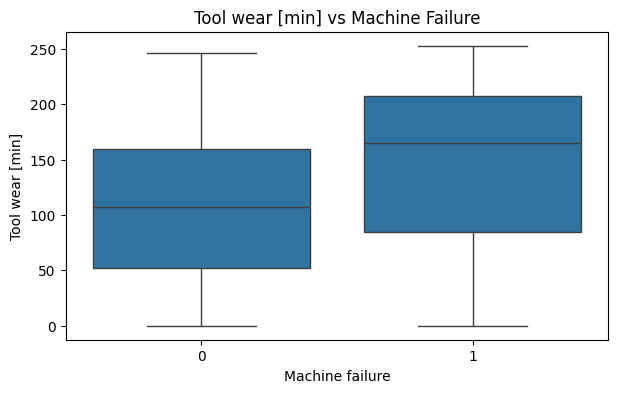

In [ ]:
for column in numerical_features:

  plt.figure(figsize = (7, 4))

  sns.boxplot( x = "Machine failure", y = column, data = df)

  plt.title(f"{column} vs Machine Failure")

  plt.show()

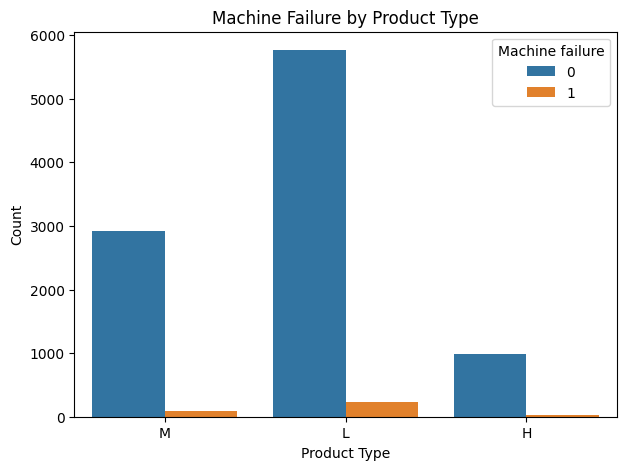

In [ ]:
plt.figure(figsize = (7, 5))

sns.countplot( x = "Type", hue = "Machine failure", data=df)

plt.title("Machine Failure by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Count")

plt.show()

In [ ]:
X = df[
    [
      "Type",
      "Air temperature [K]",
      "Process temperature [K]",
      "Rotational speed [rpm]",
      "Torque [Nm]",
      "Tool wear [min]"
    ]
]

y = df["Machine failure"]


In [ ]:
print("Input shape:", X.shape)
print("Output shape", y.shape)

Input shape: (10000, 6)
Output shape (10000,)


In [ ]:
categorical_features = ["Type"]

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify = y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown = "ignore"), categorical_features)
    ]
)

In [ ]:
linear_svm = Pipeline(
    steps=[("preprocessor", preprocessor), ("classifier", SVC(kernel = "linear"))]
)

linear_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [ ]:
y_pred_linear = linear_svm.predict(X_test)

In [ ]:
accuracy_linear = accuracy_score(y_test, y_pred_linear)

precision_linear = precision_score(y_test, y_pred_linear)

recall_linear = recall_score(y_test, y_pred_linear)

f1_linear = f1_score(y_test, y_pred_linear)

print("Accuracy :", accuracy_linear)
print("Precision :", precision_linear)
print("Recall :", recall_linear)
print("F1 Score :", f1_linear)

Accuracy : 0.966
Precision : 0.0
Recall : 0.0
F1 Score : 0.0


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_linear,
        target_names = ["No Failure", "Failure"],
        zero_division = 0
    )
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



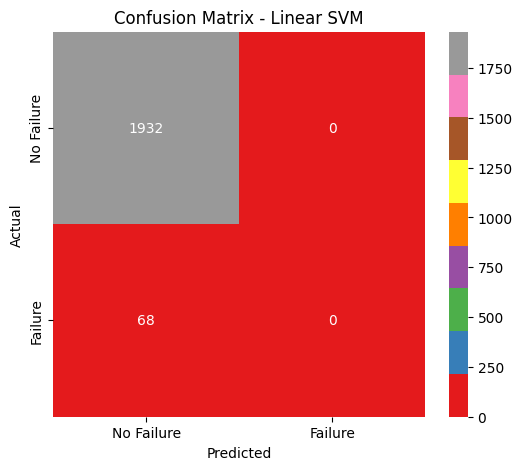

In [ ]:
cm_linear = confusion_matrix(y_test, y_pred_linear)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_linear,
    annot = True,
    fmt = "d",
    cmap = "Set1",
    xticklabels = ["No Failure", "Failure"],
    yticklabels = ["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Linear SVM")

plt.show()

In [ ]:
rbf_svm = Pipeline(
    steps=[("preprocessor", preprocessor),
     ("classifier", SVC(kernel = "rbf"))])
rbf_svm.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [ ]:
y_pred_rbf = rbf_svm.predict(X_test)

In [ ]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

precision_rbf = precision_score(y_test, y_pred_rbf)

recall_rbf = recall_score(y_test, y_pred_rbf)

f1_rbf = f1_score(y_test, y_pred_rbf)

print("RBF SVM Results")
print("Accuracy :", accuracy_rbf)
print("Precision :", precision_rbf)
print("Recall :", recall_rbf)
print("F1 Score :", f1_rbf)
#

RBF SVM Results
Accuracy : 0.972
Precision : 0.875
Recall : 0.20588235294117646
F1 Score : 0.3333333333333333


In [ ]:
print(classification_report(y_test, y_pred_rbf, target_names = ["No Failure", "Failure"], zero_division = 0))

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.99      1932
     Failure       0.88      0.21      0.33        68

    accuracy                           0.97      2000
   macro avg       0.92      0.60      0.66      2000
weighted avg       0.97      0.97      0.96      2000



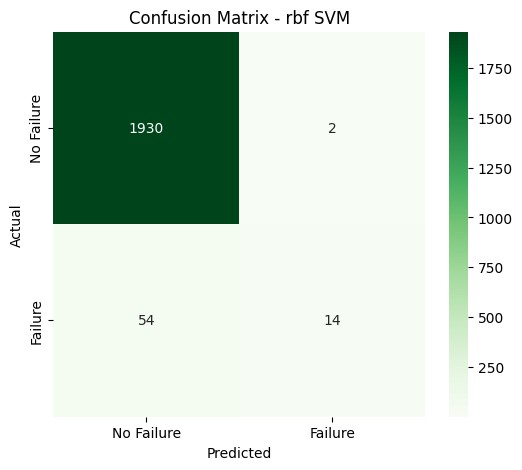

In [ ]:
cm_rbf = confusion_matrix(y_test, y_pred_rbf)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_rbf,
    annot = True,
    fmt = "d",
    cmap = "Greens",
    xticklabels = ["No Failure", "Failure"],
    yticklabels = ["No Failure", "Failure"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - rbf SVM")

plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf],
    "Precision": [precision_linear, precision_rbf],
    "Recall": [recall_linear, recall_rbf],
    "F1 Score": [f1_linear, f1_rbf]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Linear SVM,0.966,0.000,0.000000,0.000000
1,RBF SVM,0.972,0.875,0.205882,0.333333


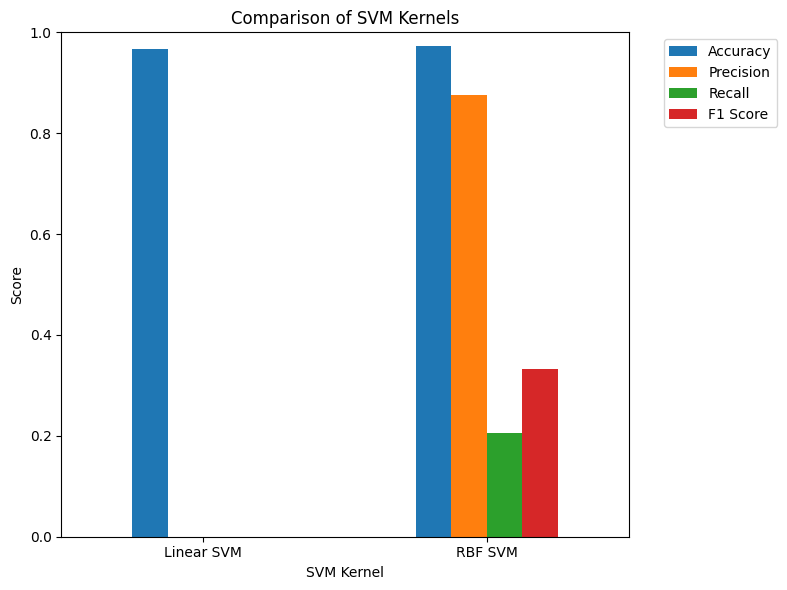

In [ ]:
comparison_plot = comparison.set_index("Model")

comparison_plot.plot(
    kind = "bar",
    figsize = (8, 6),
)
plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM Kernel")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation = 0)

plt.legend(bbox_to_anchor = (1.05, 1), loc = "upper left")

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
pipeline = Pipeline(
    steps = [("preprocessor", preprocessor), ("classifier", SVC())])


In [ ]:
param_grid = [{"classifier__kernel": ["linear"], "classifier__C":[0.1, 1, 10, 100]},
              {"classifier__kernel":["rbf"],
               "classifier__C": [0.1, 1, 10, 100], "classifier__gamma":["scale", 0.01, 0.1, 1]}]

In [ ]:
grid_search = GridSearchCV(estimator = pipeline, param_grid = param_grid, cv = 5, scoring = "f1", n_jobs = -1, verbose = 1)

In [ ]:
grid_search.fit(X_train, y_train)

print("GridSearch CV completed")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'rbf'}


In [ ]:
print("Best Parameter")
print(grid_search.best_params_)

In [ ]:
print("Best Cross-Validation F1-score: ", grid_search.best_score_)

In [ ]:
best_model = grid_search.best_estimator_

y_pred_tuned = best_model.predict(X_test)

In [ ]:
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)

precision_tuned = precision_score(y_test, y_pred_tuned)

recall_tuned = recall_score(y_test, y_pred_tuned)

f1_tuned = f1_score(y_test, y_pred_tuned)

print("Tuned SVM Results")
print("Accuracy :", accuracy_tuned)
print("Precision :", precision_tuned)
print("Recall :", recall_tuned)
print("F1 Score :", f1_tuned)

In [ ]:
final_comparison = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Tuned SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_tuned],
    "Precision": [precision_linear, precision_rbf, precision],
    "Recall ": [recall_linear, recall_rbf, recall_tuned],
    "F1 Score": [f1_linear, f1_rbf, f1_tuned]
})

final_comparison

In [ ]:
final_comparison.set_index("Model").plot(kind = "bar", figsize = (11, 6))

plt.title("Comparison of SVM Kernels")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation = 0)

plt.legend(bbox_to_anchor = (1.05, 1), loc = "upper left")

plt.tight_layout()
plt.show()
